# Notebook 03 - Thresholding and cleaning

*Time: about 50-60 minutes*

## What you will learn
- **Thresholding**: turning a gray picture into pure black and white.
- How to read a **histogram** and find the **valley** that separates text from paper.
- **Otsu's method** (the computer picks the threshold) and **adaptive** thresholding (for uneven light).
- **Blurring** to reduce noise (Gaussian and median).
- **Morphology**: erode, dilate, open and close.
- The golden rule of this course: **white object on black background (foreground = 255)**.

## Prerequisites
- Notebooks 01 and 02 (arrays, slicing, grayscale).

### What this code does

We load the libraries. `numpy` is needed for the small "kernel" grids used in morphology, and `matplotlib` draws the histogram.

In [1]:
import sys                                    # lets us change where Python looks for files
sys.path.append("..")                         # also look one folder up (utils.py lives there)
import cv2                                    # OpenCV
import numpy as np                            # NumPy: grids of numbers
import matplotlib.pyplot as plt               # matplotlib: graphs
from utils import load, show, show_many       # our helpers
print("Libraries loaded - ready to go!")      # a visible sign that everything worked

Libraries loaded - ready to go!


### What you should see / Why we care

`Libraries loaded - ready to go!`

### What this code does

Here are all the pictures for this notebook. `IMAGE_PATH` is the main one: noisy text, perfect for learning about cleaning. We convert it to gray, because thresholding needs **one** number per pixel.

gray shape: (175, 553)  smallest: 0  largest: 254


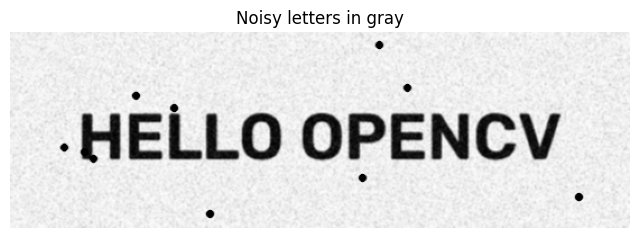

In [2]:
IMAGE_PATH = "../assets/letters_noisy.png"            # <- main picture (change me!)
SKEWED_PATH = "../assets/letters_skewed.png"          # tilted text
DIGITS_PATH = "../assets/digits_single.png"           # digits 0-9
PHOTO_PATH = "../assets/digits_grid_photo_like.png"   # uneven lighting
noisy = cv2.cvtColor(load(IMAGE_PATH), cv2.COLOR_BGR2GRAY)  # colour -> gray
print("gray shape:", noisy.shape, " smallest:", noisy.min(), " largest:", noisy.max())
show(noisy, "Noisy letters in gray", size=(8, 3))    # look at it

### What you should see / Why we care

`gray shape: (175, 553)`, smallest `0`, largest `254` (the noise nudges even the paper), and a picture of **grainy text with a few dark specks**. This is what a bad photo or scan looks like.

### What this code does

A **histogram** counts how many pixels have each brightness (0 = black ... 255 = white). Text is dark, paper is bright, so we expect **two hills**. The **valley** between the hills is a good place to cut. `noisy.ravel()` just flattens the grid into one long list of numbers.

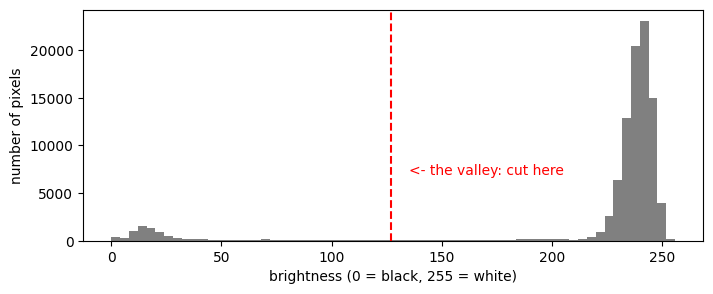

In [3]:
plt.figure(figsize=(8, 3))                              # empty figure
counts, edges, patches = plt.hist(noisy.ravel(), bins=64, range=(0, 256), color="gray")
plt.axvline(127, color="red", linestyle="--")           # red line at 127
plt.text(135, counts.max() * 0.3, "<- the valley: cut here", color="red")  # note
plt.xlabel("brightness (0 = black, 255 = white)")       # explain x axis
plt.ylabel("number of pixels")                          # explain y axis
plt.show()                                              # draw it

### What you should see / Why we care

**One big hill on the right** (the white paper, around 255) and a **small hill on the left** (the dark text). Between them is a **valley** with few pixels. Any threshold in the valley separates text from paper.

### What this code does

**Binary threshold.** `cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)` means: *"pixels brighter than 127 become 255 (white), all others become 0 (black)."* It returns two things: the value used and the new picture.

threshold used: 127.0
different values now: [  0 255]


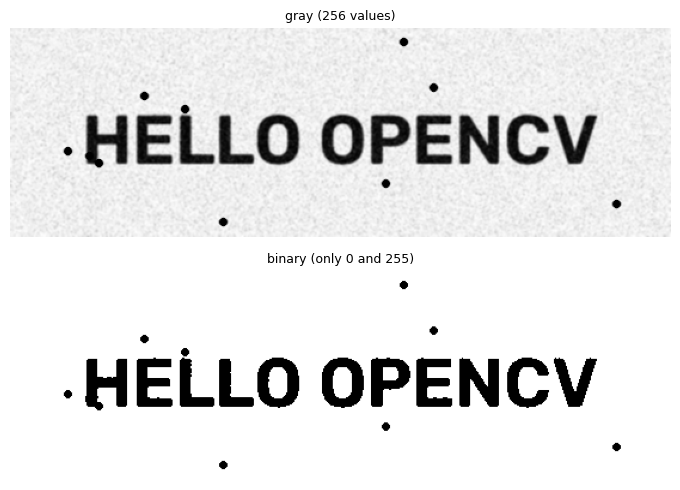

In [4]:
used, binary = cv2.threshold(noisy, 127, 255, cv2.THRESH_BINARY)  # fixed cut at 127
print("threshold used:", used)                       # we chose 127 ourselves
print("different values now:", np.unique(binary))   # only 0 and 255 are left!
show_many([noisy, binary], ["gray (256 values)", "binary (only 0 and 255)"],
          columns=1, size=(8, 5))                    # compare

### What you should see / Why we care

`different values now: [  0 255]`. The picture is pure black and white. Some noise became black dots, but the letters are clear.

### What this code does

**Otsu's method.** Instead of guessing 127, we pass `0` and add `cv2.THRESH_OTSU`. OpenCV tries **every** threshold from 0 to 255 and keeps the one that separates the two hills best (the smallest "spread" inside each group). It also tells us the number it picked.

Otsu chose: 135.0


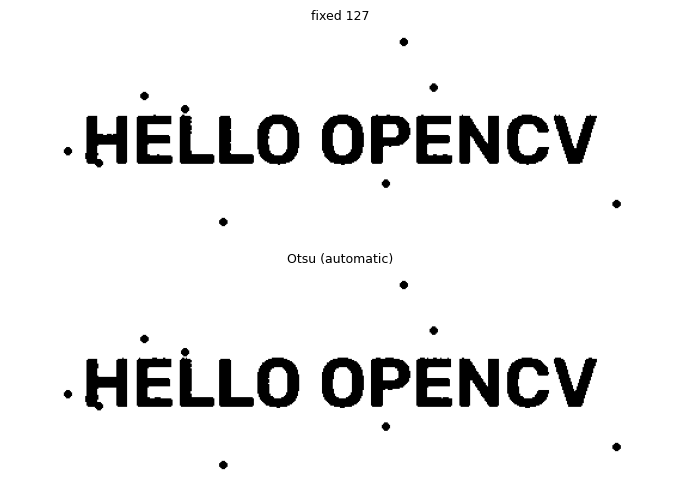

In [5]:
otsu_value, otsu = cv2.threshold(noisy, 0, 255,
                                 cv2.THRESH_BINARY + cv2.THRESH_OTSU)  # automatic!
print("Otsu chose:", otsu_value)                     # the number it picked
show_many([binary, otsu], ["fixed 127", "Otsu (automatic)"], columns=1, size=(8, 5))

### What you should see / Why we care

Otsu prints `Otsu chose: 135.0`, a number inside the valley. **Why we care:** a new picture with different lighting needs a different threshold, and Otsu finds it for us.

### What this code does

**Adaptive threshold.** Otsu uses **one** number for the whole picture. If the light is uneven (a shadow, or a dark corner) one number fails. *Adaptive* thresholding decides **pixel by pixel**, by comparing each pixel with its neighbours (the block of 31 x 31 pixels around it). The `10` is a small number subtracted to ignore tiny differences.
Here we use it on the **tilted** picture.

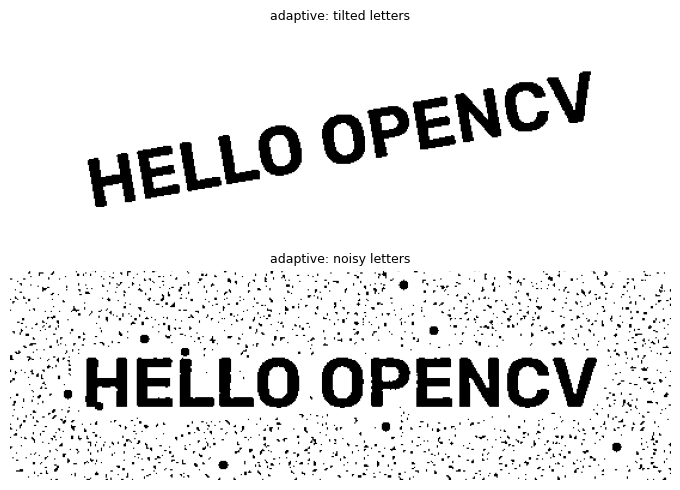

In [6]:
skewed = cv2.cvtColor(load(SKEWED_PATH), cv2.COLOR_BGR2GRAY)  # tilted text in gray
adaptive_skewed = cv2.adaptiveThreshold(skewed, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, 31, 10)   # local decision
adaptive_noisy = cv2.adaptiveThreshold(noisy, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                       cv2.THRESH_BINARY, 31, 10)    # on noisy text
show_many([adaptive_skewed, adaptive_noisy], ["adaptive: tilted letters", "adaptive: noisy letters"],
          columns=1, size=(8, 5))

### What you should see / Why we care

The tilted text comes out **crisp**. The noisy text comes out **full of grains**, because adaptive thresholding reacts to every little noise bump. Cleaning (blurring) first is the cure. We do that in a moment.

### What this code does

Now the situation where adaptive **wins**: a photo with a dark vignette (corners darker than the centre). We try Otsu (one number) and adaptive (local) on the photo-like picture. We will need this again in Notebook 08.

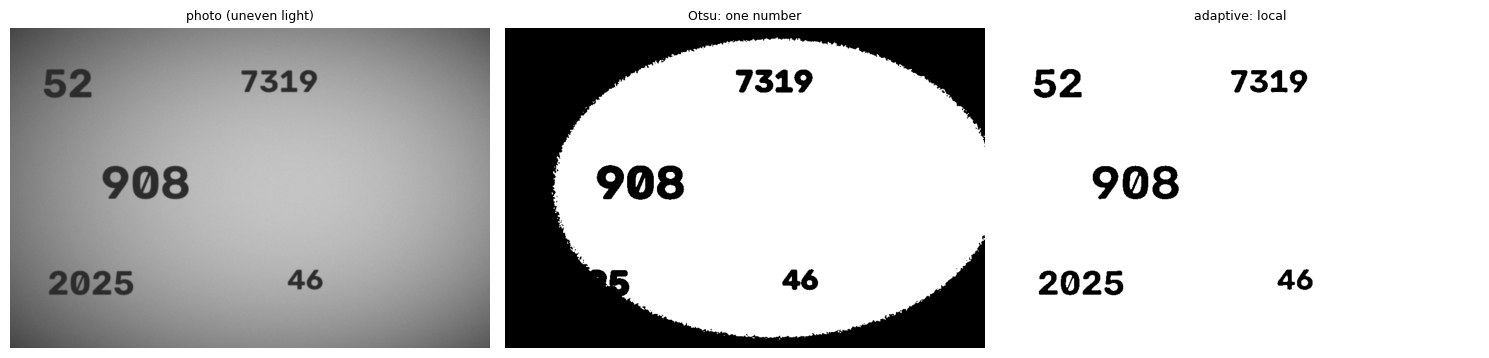

In [7]:
photo = cv2.cvtColor(load(PHOTO_PATH), cv2.COLOR_BGR2GRAY)   # photo-like picture
blur = cv2.GaussianBlur(photo, (5, 5), 0)                    # small blur first
_, photo_otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
photo_adaptive = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                       cv2.THRESH_BINARY, 51, 10)  # local decision
show_many([photo, photo_otsu, photo_adaptive],
          ["photo (uneven light)", "Otsu: one number", "adaptive: local"], columns=3, size=(15, 4))

### What you should see / Why we care

**Otsu** loses numbers in the dark corners (the dark vignette becomes a big black blob). **Adaptive** keeps every number clean. Rule of thumb: even light = Otsu, uneven light = adaptive.

## Cleaning noise with blur

A blur replaces each pixel by an average of its neighbours, which smooths away random noise.
- **Gaussian blur**: a weighted average (soft and smooth).
- **Median blur**: takes the *middle value* of the neighbours. Great against random dark/bright dots.

### What this code does

We apply both blurs to the noisy gray picture. The second number is the size of the neighbourhood (it must be odd: 3, 5, 7...). To measure the noise we take an empty patch of paper (`noisy[0:40, 0:200]`) and compute its **standard deviation** (how much the numbers wobble). A clean patch should wobble very little.

noisy - wobble of empty paper: 5.7
gaussian - wobble of empty paper: 3.5
median - wobble of empty paper: 2.8


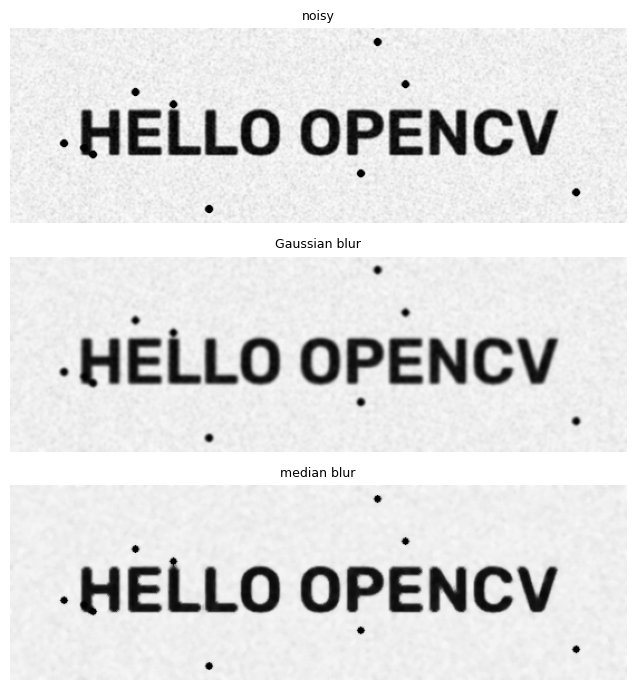

In [8]:
gaussian = cv2.GaussianBlur(noisy, (5, 5), 0)           # weighted average of 5x5 pixels
median = cv2.medianBlur(noisy, 5)                       # middle value of 5x5 pixels
for name, picture in [("noisy", noisy), ("gaussian", gaussian), ("median", median)]:
    wobble = picture[0:40, 0:200].std()                 # spread of an empty paper patch
    print(name, "- wobble of empty paper:", round(float(wobble), 1))   # smaller = cleaner
show_many([noisy, gaussian, median], ["noisy", "Gaussian blur", "median blur"], columns=1, size=(8, 7))

### What you should see / Why we care

The wobble of the empty paper drops from about **5.7** (noisy) to **3.5** (Gaussian) to **2.8** (median). The median result has crisper letter edges than Gaussian.

### What this code does

Does cleaning first make thresholding better? We run Otsu three times: on the raw picture, after Gaussian and after median.

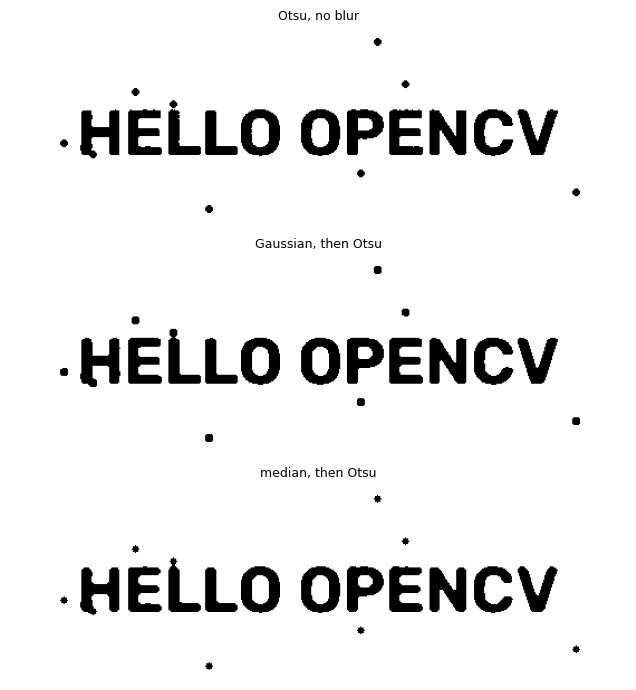

In [9]:
_, raw_otsu = cv2.threshold(noisy, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, gauss_otsu = cv2.threshold(gaussian, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, median_otsu = cv2.threshold(median, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
show_many([raw_otsu, gauss_otsu, median_otsu],
          ["Otsu, no blur", "Gaussian, then Otsu", "median, then Otsu"], columns=1, size=(8, 7))

### What you should see / Why we care

Without blur the letters have **ragged edges and grains**. After blur they are smooth. The median version is the cleanest. The big dust specks remain; we remove those later with an **area filter** (Notebook 04).

## The golden rule: white on black

OpenCV's contour tools (Notebook 04) look for **white things on a black background**. So before contour work we always make sure that **foreground = 255 (white)** and **background = 0 (black)**. Otsu gave us *black text on white paper*, so we must **flip** it.

### What this code does

`cv2.bitwise_not` flips every pixel: 0 becomes 255 and 255 becomes 0. We count the white pixels (`cv2.countNonZero`) before and after to prove the flip.

white pixels BEFORE flip (the paper): 88023
white pixels AFTER flip  (the text) : 8752


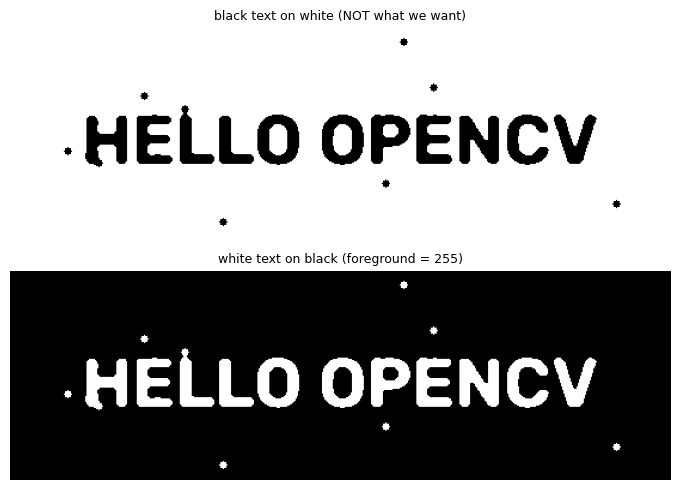

In [10]:
white_on_black = cv2.bitwise_not(median_otsu)           # flip: text is now 255
print("white pixels BEFORE flip (the paper):", cv2.countNonZero(median_otsu))
print("white pixels AFTER flip  (the text) :", cv2.countNonZero(white_on_black))
show_many([median_otsu, white_on_black], ["black text on white (NOT what we want)",
          "white text on black (foreground = 255)"], columns=1, size=(8, 5))

### What you should see / Why we care

Before the flip most pixels are white (paper). After the flip only a **small number** of white pixels remain: the letters. Memorise: **the thing you care about must be white.**
(You can also do both steps at once with `cv2.THRESH_BINARY_INV`.)

## Morphology: reshaping white shapes

Morphology slides a tiny square (the **kernel**) over the picture.
- **Erode**: shrinks white shapes (removes thin bits and specks).
- **Dilate**: grows white shapes (fills tiny gaps).
- **Open** = erode then dilate: *removes specks, keeps letter size*.
- **Close** = dilate then erode: *joins broken strokes, keeps letter size*.

### What this code does

We prepare a clean white-on-black picture of the digits 0-9 and a 3 x 3 kernel (a small grid of ones). Then we erode and dilate it and count white pixels.

white pixels: original 11771 | eroded 8975 | dilated 14577


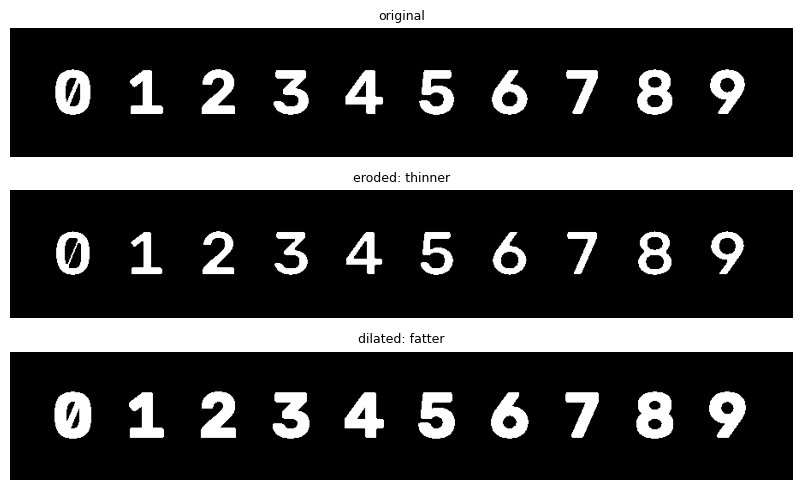

In [11]:
digits_gray = cv2.cvtColor(load(DIGITS_PATH), cv2.COLOR_BGR2GRAY)         # gray digits
_, digits = cv2.threshold(digits_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
kernel = np.ones((3, 3), np.uint8)                       # a 3x3 grid of ones
eroded = cv2.erode(digits, kernel, iterations=1)         # shrink
dilated = cv2.dilate(digits, kernel, iterations=1)       # grow
print("white pixels: original", cv2.countNonZero(digits), "| eroded", cv2.countNonZero(eroded),
      "| dilated", cv2.countNonZero(dilated))
show_many([digits, eroded, dilated], ["original", "eroded: thinner", "dilated: fatter"], columns=1, size=(10, 5))

### What you should see / Why we care

Eroded digits are **thinner** (fewer white pixels), dilated digits are **fatter** (more white pixels).

### What this code does

**Opening removes specks.** We sprinkle 40 single white pixels (like dust) over the black background. `np.random.seed(5)` makes the "random" dust the same every time. Then `cv2.MORPH_OPEN` erases them.

white pixels: clean 11771 | dusty 11811 | opened 11765


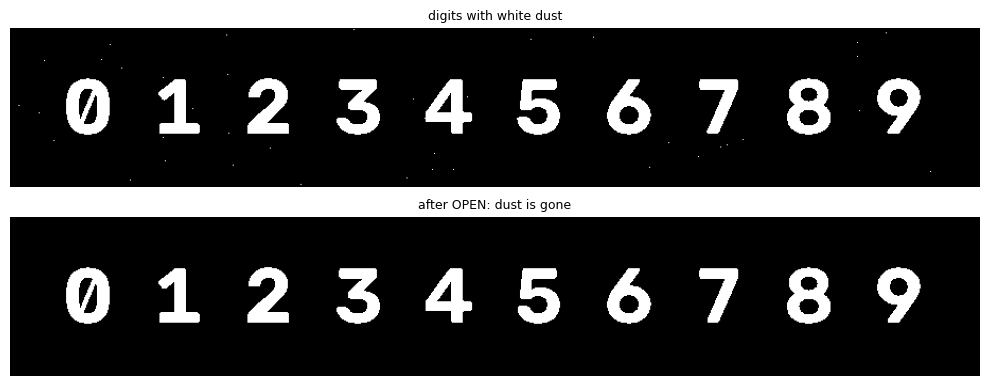

In [12]:
np.random.seed(5)                                         # same dust every run
specks = digits.copy()                                    # copy of the clean digits
for i in range(40):                                       # 40 dust particles
    specks[np.random.randint(0, 150), np.random.randint(0, 915)] = 255  # one white pixel
opened = cv2.morphologyEx(specks, cv2.MORPH_OPEN, kernel)  # erode, then dilate
print("white pixels: clean", cv2.countNonZero(digits), "| dusty", cv2.countNonZero(specks), "| opened", cv2.countNonZero(opened))
show_many([specks, opened], ["digits with white dust", "after OPEN: dust is gone"], columns=1, size=(10, 4))

### What you should see / Why we care

The dusty count is about 40 higher than the clean count; after opening it is back to (almost exactly) the clean count.

### What this code does

**Closing joins broken strokes.** We pretend the printer ran out of ink: a thin black line is drawn across all digits (`cv2.line`), cutting each digit into two pieces. A bigger 5 x 5 kernel and `cv2.MORPH_CLOSE` (dilate, then erode) glue the pieces back.

white pixels: broken 11043 | closed 11767


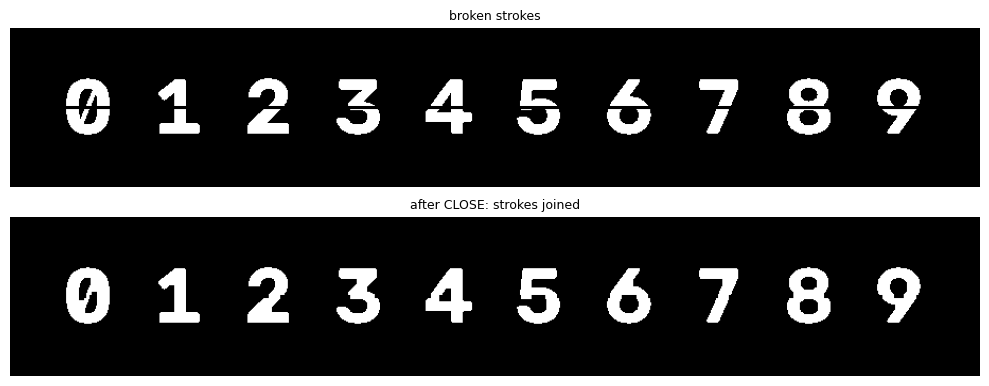

In [13]:
broken = digits.copy()                                    # copy of the clean digits
cv2.line(broken, (0, 75), (915, 75), 0, 2)                # black line across everything
kernel5 = np.ones((5, 5), np.uint8)                       # a bigger kernel
closed = cv2.morphologyEx(broken, cv2.MORPH_CLOSE, kernel5)  # dilate, then erode
print("white pixels: broken", cv2.countNonZero(broken), "| closed", cv2.countNonZero(closed))
show_many([broken, closed], ["broken strokes", "after CLOSE: strokes joined"], columns=1, size=(10, 4))

### What you should see / Why we care

The cut line disappears and every digit is **one connected piece again**. **Why we care:** a broken letter would be found as *two* objects by the contour finder. Closing fixes that.

### What this code does

Now we put the whole **cleaning recipe** in one place. We will reuse it in the next notebooks: gray, median blur, Otsu, flip.

final picture values: [  0 255] | white pixels: 8752


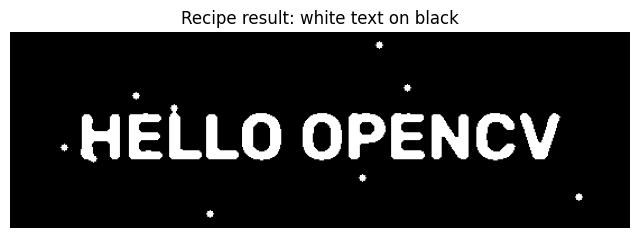

In [14]:
gray = cv2.cvtColor(load(IMAGE_PATH), cv2.COLOR_BGR2GRAY)   # 1. gray
blur = cv2.medianBlur(gray, 5)                              # 2. remove noise
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)  # 3. black/white
thresh = cv2.bitwise_not(thresh)                            # 4. white text on black
print("final picture values:", np.unique(thresh), "| white pixels:", cv2.countNonZero(thresh))
show(thresh, "Recipe result: white text on black", size=(8, 3))

### What you should see / Why we care

`final picture values: [  0 255]` and clean white letters (plus a few dust blobs) on black. **This `thresh` picture is the starting point for contours in Notebook 04.**

## Recap
| Goal | Tool |
|---|---|
| Fixed cut | `cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)` |
| Automatic cut | add `cv2.THRESH_OTSU` |
| Uneven light | `cv2.adaptiveThreshold(...)` |
| Reduce noise | `cv2.GaussianBlur`, `cv2.medianBlur` |
| Flip to white-on-black | `cv2.bitwise_not` |
| Remove specks / join breaks | `cv2.MORPH_OPEN` / `cv2.MORPH_CLOSE` |

**Next:** Notebook 04 finds each white shape and draws a box around it.